# Educational Inequality and ACT Scores in U.S. High Schools

## 1. Project Description

Analyzing the relationship between socioeconomic factors and ACT scores across 7,227 U.S. high schools using statistical analysis and linear regression to explore educational inequality and differences between states.

### 1.1 Data Source

This project uses the **EdGap dataset**, which provides school-level average ACT scores (or SAT-equivalent scores) and socioeconomic characteristics, along with public school information from the **National Center for Education Statistics (NCES)**.

**Sources:**
- **EdGap:** Dataset provided by the professor for this project.
- **NCES Common Core of Data (2016–2017):** [https://nces.ed.gov/ccd/](https://nces.ed.gov/ccd/)

The datasets were combined using school identification numbers to investigate relationships between socioeconomic factors and academic performance across U.S. high schools.

## 2. Data collection

### 2.1 Load the data

#### Import libraries

In [10]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

import plotly.offline as po
import plotly.graph_objs as pg

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

Those are the libraries we will be using to help with data cleaning, manipulation, and visualization. 

#### Load the EdGap data set

In [13]:
edgap = pd.read_excel('/Users/marianabutarov/Desktop/Data Science/Foundations of Data Science /Week 3/EdGap_data.xlsx',
                     dtype = {'NCESSCH School ID': object})

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/worksheet/_read_only.py:81: UserWarning:

Unknown extension is not supported and will be removed



#### Load the school information data

In [15]:
school_information = pd.read_csv('/Users/marianabutarov/Desktop/Data Science/Foundations of Data Science /Week 3/ccd_sch_029_1617_w_1a_11212017.csv',
                                encoding = 'unicode_escape')

/var/folders/j1/t6wf96vj4hq1p8zg7blqq7km0000gn/T/ipykernel_49176/2940856153.py:1: DtypeWarning:

Columns (6,9,14,15,18,19,21,22,25,26,29,31,35,39,41,42) have mixed types. Specify dtype option on import or set low_memory=False.



### 2.2 Explore the contents of the data sets

#### Start by looking at the head of each data frame.
This will let us see the names of the columns and a few example values for each column. We can also check whether the data is in tidy format.

In [18]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [19]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,...,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported


In [20]:
pd.set_option('display.max_columns', None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


This will let us see all the columns we could not see only with head() method.

#### Use the info method to check the data types, size of the data frame, and numbers of missing values

In [23]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [24]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  object 
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  object 
 3   ST                   102183 non-null  object 
 4   SCH_NAME             102183 non-null  object 
 5   LEA_NAME             102183 non-null  object 
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  object 
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  object 
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  object 
 14  MSTREET2             1825 non-null    object 
 15  MSTREET3         

After looking at both datasets, I noticed that the school information dataset contains many more schools than the EdGap dataset. This means that EdGap does not include information about every school. Both datasets also have some missing information that needs to be handled before the analysis. The data is organized in a similar way, with each row representing a school and each column showing information about that school. Most of the data is stored correctly, but the school IDs have different formats in the two datasets. These need to be made consistent so the information from both datasets can be combined correctly.

### 2.3 Exploring with visualizations

#### Make a pair plot to explore relationships between the variables.

<function matplotlib.pyplot.show(close=None, block=None)>

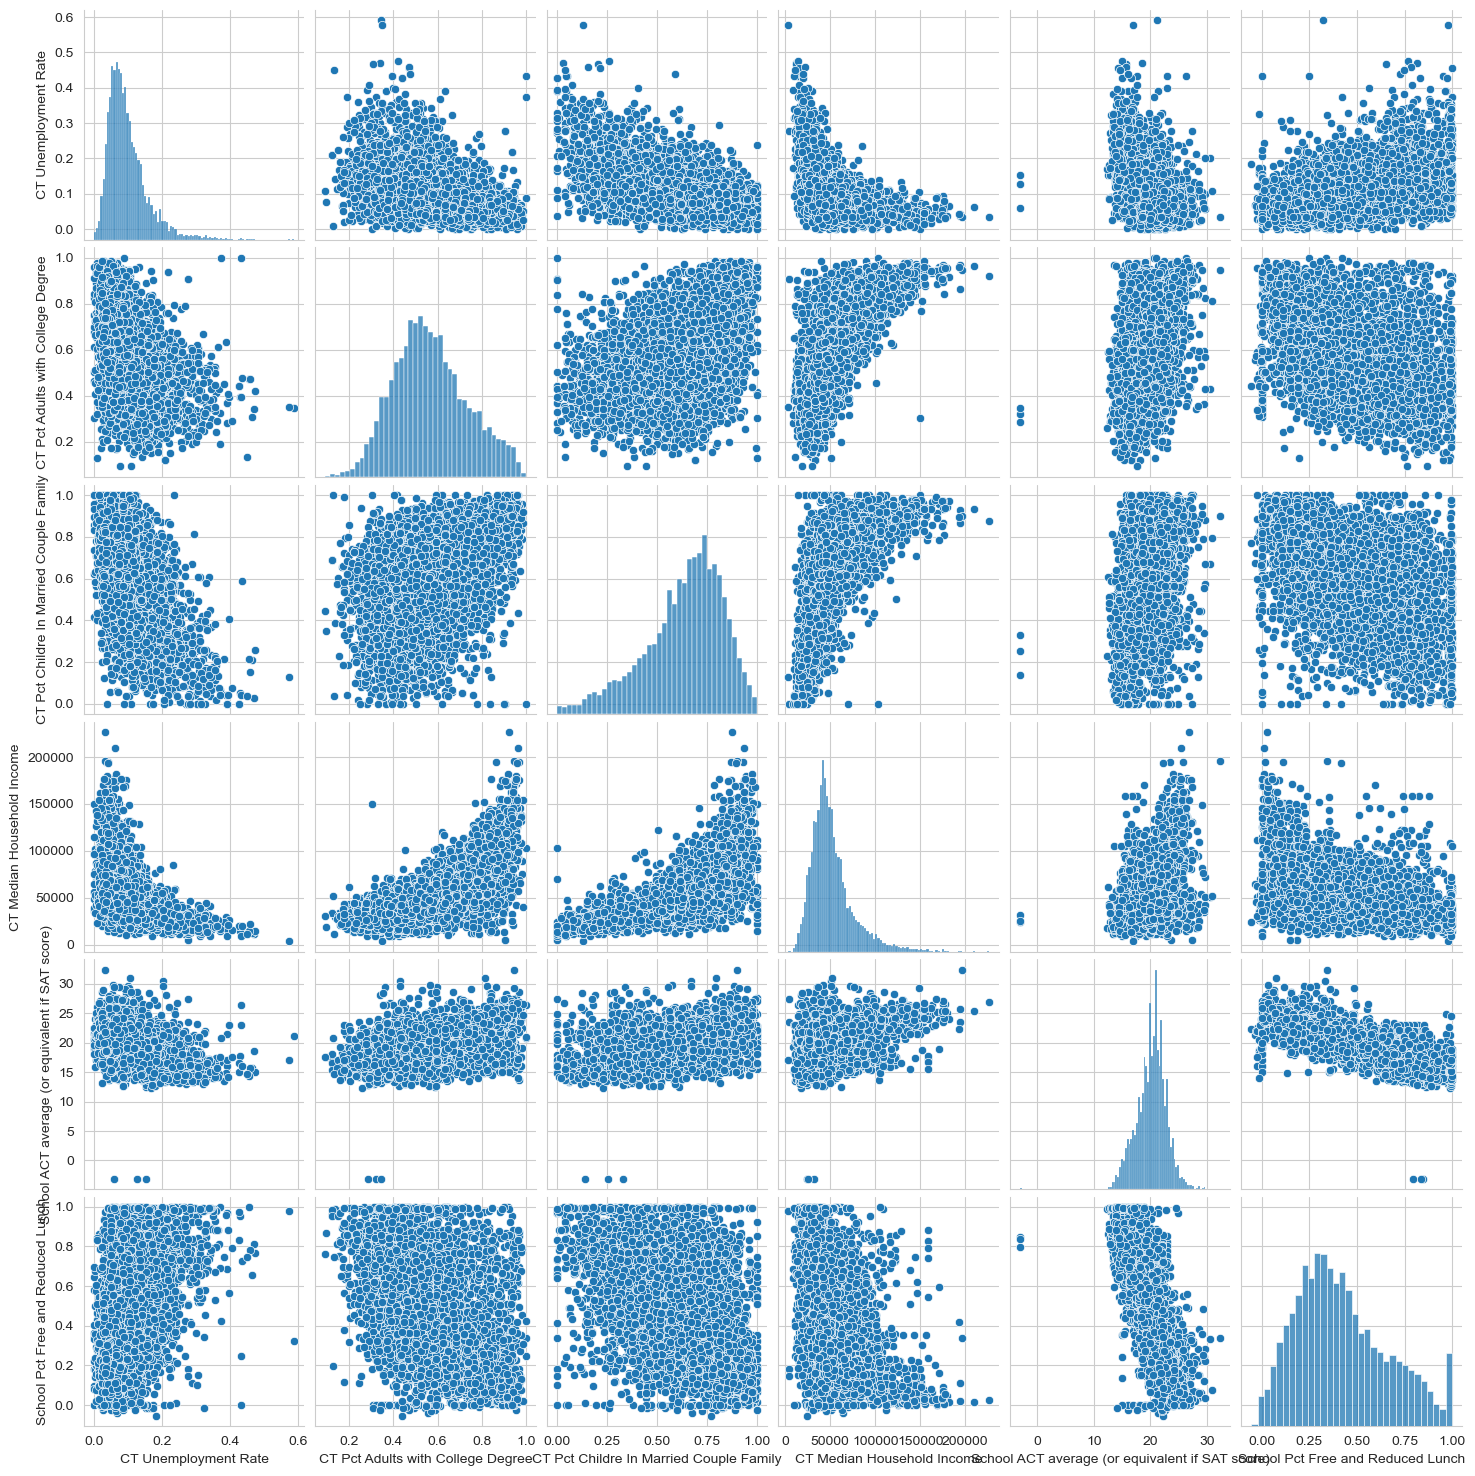

In [28]:
sns.pairplot(edgap.drop(columns='NCESSCH School ID'))
plt.show

The pair plot shows how socioeconomic factors relate to each other and to average ACT scores. Schools in areas with higher college education levels and household incomes tend to have higher ACT scores. On the other hand, schools with higher unemployment rates and more students receiving free or reduced-price lunch tend to have lower ACT scores. The relationship between lunch eligibility and ACT scores appears particularly strong.

The plot also shows that some socioeconomic factors are related to each other. For example, areas with higher household incomes tend to have higher college education levels and lower unemployment rates. Although these patterns are noticeable, the data points are spread out, meaning other factors may also influence ACT scores.

#### Add regression lines and format the pair plot

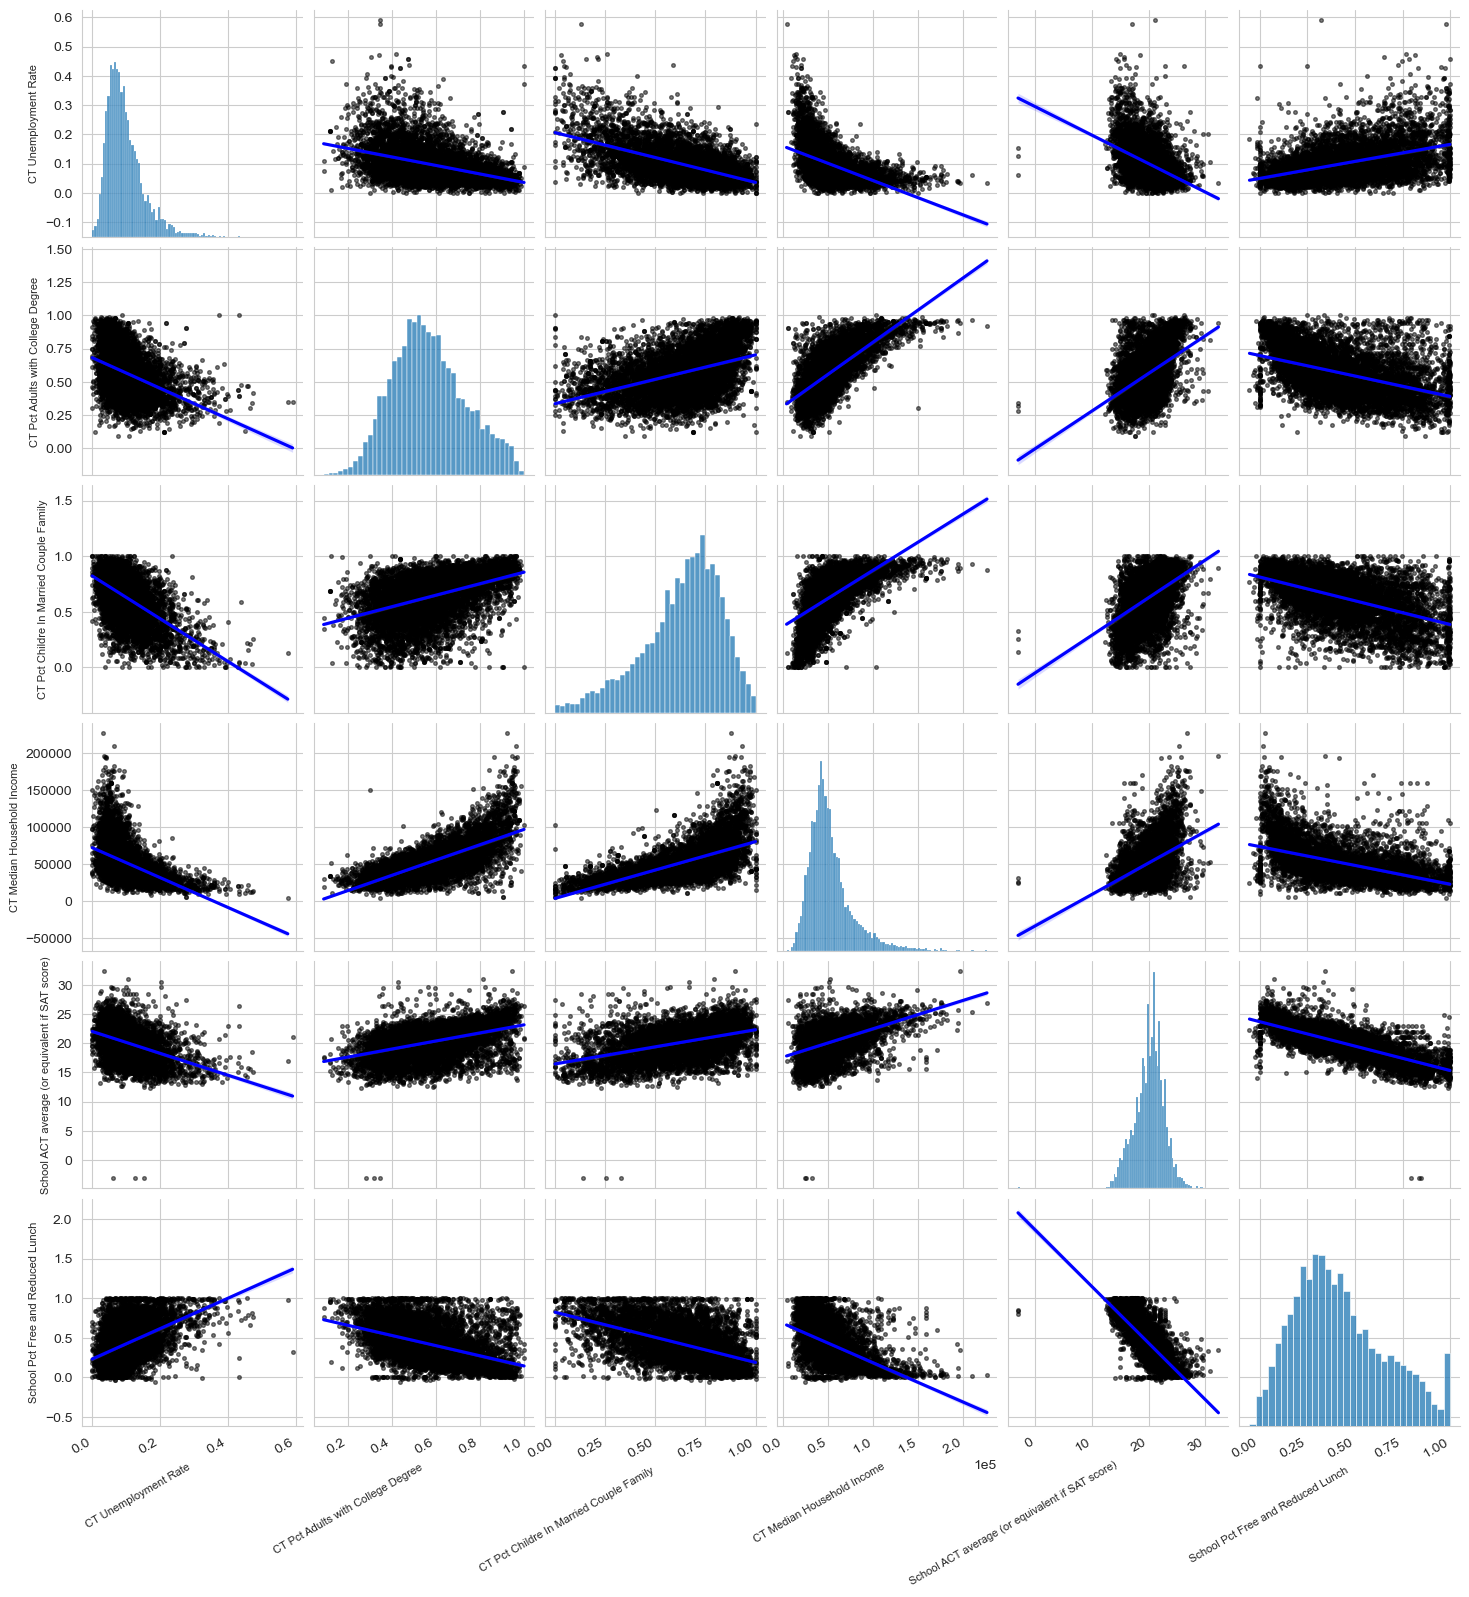

In [31]:
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws':{'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Feature related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

Adding regression lines to the pair plot makes the relationships easier to see. The lines show that higher college education levels and household incomes are generally linked to higher ACT scores, while higher unemployment and free or reduced-price lunch rates are linked to lower scores.

#### Plot a single row 

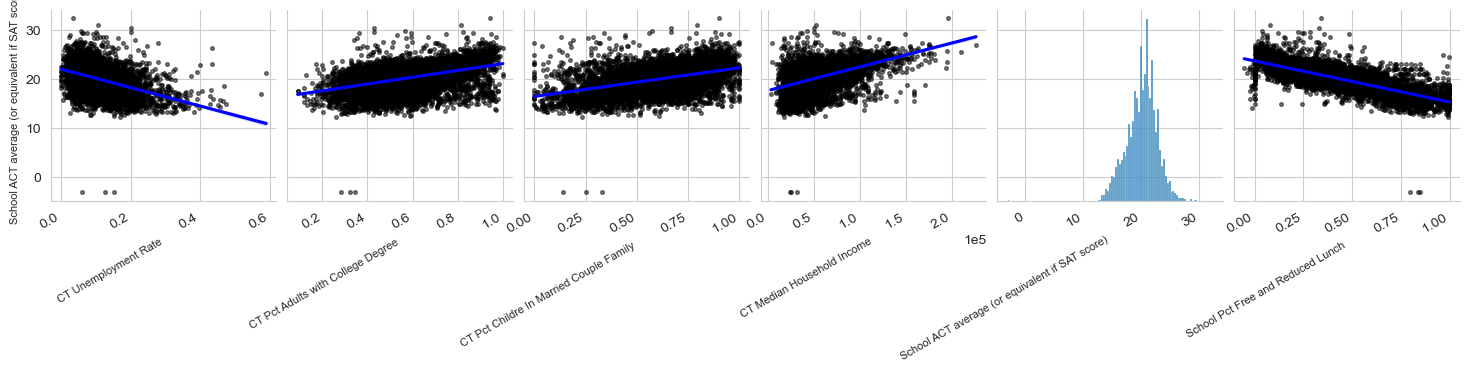

In [34]:
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    y_vars = ['School ACT average (or equivalent if SAT score)'],
    kind = 'reg', # Add regression line
    plot_kws = {
        'line_kws':{'color': 'blue'}, # Features related to lines
        'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7} # Feature related to the scatter plots
    }
)

# Further adjust the axis formatting
for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

This plot compares average ACT scores with each variable in the dataset. Each black dot represents a school, while the blue regression line shows the general trend. By placing the graphs in one row, we can more easily compare which factors have positive or negative relationships with ACT scores and how strong those relationships appear.

## 3.Data Preparation

### 3.1 Select relevant subsets of the data

The school information data set contains many columns. We only need the year, school identity, location, and school type information.

Keep the columns SCHOOL_YEAR, NCESSCH, LSTATE, LZIP, SCH_TYPE_TEXT, LEVEL, CHARTER_TEXT

In [39]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
]

In [40]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


### 3.2 Rename columns

We will rename the columns to follow best practices of style and being informative. We will do it before joining the data sets to make it obvious that they key has the same name in each data set.

In [43]:
edgap.columns

Index(['NCESSCH School ID', 'CT Unemployment Rate',
       'CT Pct Adults with College Degree',
       'CT Pct Childre In Married Couple Family', 'CT Median Household Income',
       'School ACT average (or equivalent if SAT score)',
       'School Pct Free and Reduced Lunch'],
      dtype='object')

In [44]:
edgap = edgap.rename(
    columns = {
       'NCESSCH School ID': 'id', 
       'CT Unemployment Rate': 'rate_unemployment',
       'CT Pct Adults with College Degree': 'percent_college',
       'CT Pct Childre In Married Couple Family': 'percent_married', 
       'CT Median Household Income': 'median_income',
       'School ACT average (or equivalent if SAT score)': 'average_act',
       'School Pct Free and Reduced Lunch': 'percent_lunch',
    }
)

In [45]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [46]:
school_information.columns

Index(['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL',
       'CHARTER_TEXT'],
      dtype='object')

In [47]:
school_information = school_information.rename(
    columns = {
       'NCESSCH': 'id', 
       'SCHOOL_YEAR': 'year',
       'LSTATE': 'state',
       'LZIP': 'zip_code', 
       'SCH_TYPE_TEXT': 'school_type',
       'LEVEL': 'school_level',
       'CHARTER_TEXT': 'charter',
    }
)

In [48]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


We renamed the columns to make them shorter, clearer, and easier to use during the analysis. After making these changes, we used the head() method to display the first five rows of the dataset and confirm that the column names were updated correctly. The result shows the dataset with its new column names.

### 3.3 Join data frames

We want to join the DataFrames using the identity of the school as the key. The identity is given by the NCESSCH school identity. The value is an object in the EdGap data set and a float64 in the school information data set.

We will cast the id column in the school_information DataFrame as an object.

In [52]:
school_information['id'] = school_information['id'].astype('object')

In [53]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  object
 1   id            102181 non-null  object
 2   state         102183 non-null  object
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  object
 5   school_level  102179 non-null  object
 6   charter       102179 non-null  object
dtypes: object(7)
memory usage: 5.5+ MB


#### Join the data frames and call the result df.

In [55]:
df = edgap.merge(
    school_information,
    how = 'left', # use the left join
    on = 'id'     # use id as the key
)

This is merging both dataframes into one dataframe called df, we are doing a left join which keep everything that is on the edgap dataset as it is and we bring the infomation of school_information after all the columns of edgap is over.

In [57]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   object 
 8   state              7898 non-null   object 
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   object 
 11  school_level       7898 non-null   object 
 12  charter            7898 non-null   object 
dtypes: float64(6), object(7)
memory usage: 811.2+ KB


### 3.4 Quality Control

#### Check the min and max values in each column.

In [61]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


In [62]:
df.select_dtypes(include = ['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


We selected the numerical columns and used the min and max functions to check the lowest and highest values in the dataset. The results show some unusual values, including negative numbers for average ACT scores and the percentage of students eligible for free or reduced-price lunch. Since these values should not be negative, they indicate possible errors in the data that need to be investigated during cleaning.

#### Set out-of-range values to NaN using np.nan

In [65]:
df.loc[df['percent_lunch'] < 0, 'percent_lunch'] = np.nan

In [66]:
df.loc[df['average_act'] < 1, 'average_act'] = np.nan

We replaced incorrect values with NaN (missing values) instead of deleting the entire rows. This allows us to keep useful information from the other columns while marking the incorrect values to be handled later during data cleaning.

#### Check the types, levels, and charter status of schools

In [69]:
df['school_type'].value_counts()

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64

In [70]:
df['school_level'].value_counts()

school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64

In [71]:
df['charter'].value_counts()

charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64

We used the value_counts() method to check the different categories in the school_type, school_level, and charter columns. This shows how many schools belong to each category and helps us understand the types and levels of schools in our dataset, as well as how many are charter schools. It also helps us identify any unusual or incorrect values before continuing with data cleaning.

#### Keep only high schools.

In [74]:
df = df.loc[df['school_level'] == 'High'] 

We filtered the dataset to include only high schools, since ACT scores are mainly used to measure high school students' academic performance and college readiness. This allows us to focus on the schools that are most relevant to our analysis.

#### Check for any duplicated rows

In [77]:
df.duplicated().sum()

0

We checked the dataset for duplicate rows to make sure the same information was not included more than once. Duplicate rows could affect our analysis by counting the same school multiple times, so it is important to identify them before continuing with data cleaning.

#### Identify missing values

In [80]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


We checked how many missing values (NaN) are present in each row of the dataset. This helps us understand how much information is missing for each school and decide how to handle these values during data cleaning.

In [82]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

We checked which states are included in our dataset and how many schools we have from each state. This helps us understand where our data comes from and see which states have more or fewer schools represented in the analysis.

In [84]:
df['state'].nunique()

20

We counted the number of different states represented in our dataset. This helps us understand how many states are included in our analysis and how much of the United States our data covers.

#### Plot results on a map

In [87]:
layout = dict(
    geo = {"scope": "usa"}, coloraxis_colorbar = dict(title = "Number of Schools")
)

data = dict(
    type = "choropleth",
    locations = df["state"].value_counts().index,
    locationmode = "USA-states",
    z = df["state"].value_counts().values,
    coloraxis = "coloraxis",
)

x = pg.Figure(data = [data], layout = layout)

po.iplot(x)

We created a U.S. map using colors to show how many schools are included in our dataset from each state. States with more schools have different color intensities than those with fewer schools. The map also helps us identify which states have no data available, showing that our dataset does not cover the entire country.

#### Drop the rows where the average ACT score is missing.

In [90]:
df = df.dropna(subset = ['average_act'])

In [91]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


If we drop rows that have NaNs for any socioeconomic variables, then we will negatively affect our analysis. We don't want to drop the entire row just because one socioeconomic variable is missing, because we would also lose the useful information that is available in the other variables. We will impute the missing values.

#### Using one-hot encoding to tranform states as numerical

In [94]:
state_dummies = pd.get_dummies(df['state'], prefix='State', dtype=int)

df = pd.concat([df, state_dummies], axis=1)

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7227 entries, 0 to 7985
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7227 non-null   object 
 1   rate_unemployment  7215 non-null   float64
 2   percent_college    7216 non-null   float64
 3   percent_married    7207 non-null   float64
 4   median_income      7211 non-null   float64
 5   average_act        7227 non-null   float64
 6   percent_lunch      7207 non-null   float64
 7   year               7227 non-null   object 
 8   state              7227 non-null   object 
 9   zip_code           7227 non-null   object 
 10  school_type        7227 non-null   object 
 11  school_level       7227 non-null   object 
 12  charter            7227 non-null   object 
 13  State_DE           7227 non-null   int64  
 14  State_FL           7227 non-null   int64  
 15  State_GA           7227 non-null   int64  
 16  State_IL           7227 non-n

We converted the state column into separate columns for each state, using 1 to indicate that a school belongs to that state and 0 if it does not. We then added these new columns to our dataset. This allows us to include states as numerical variables in our statistical analysis and compare differences between them.

In [97]:
state_scores = (
    df.groupby('state')['average_act']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=True)
)

state_scores

,mean,count
state,,
DE,17.388380,24
NY,17.658968,295
LA,18.912887,194
TN,18.950943,265
KY,19.265657,198
GA,19.569073,367
MI,19.581124,498
IL,19.804787,564
WY,19.989474,38


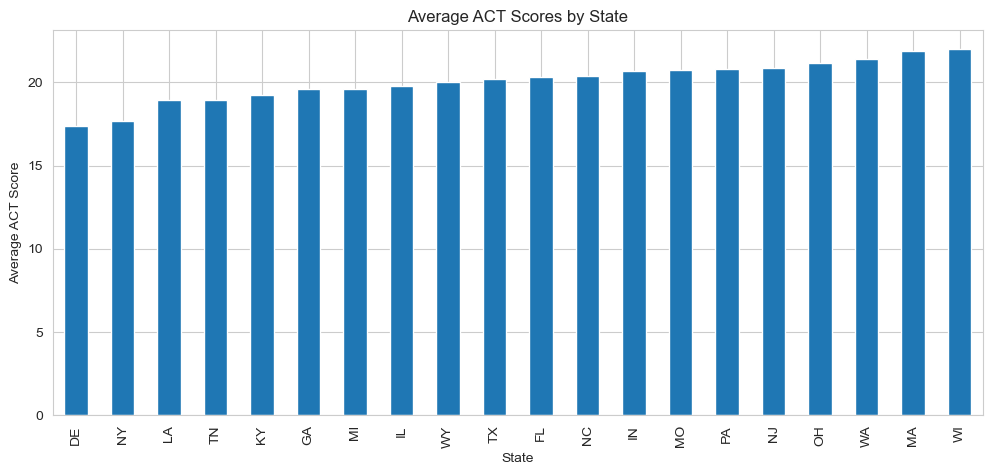

In [98]:
state_scores['mean'].plot(kind='bar', figsize=(12, 5))

plt.title('Average ACT Scores by State')
plt.xlabel('State')
plt.ylabel('Average ACT Score')
plt.show()

We grouped the schools by state and calculated the average ACT score and the number of schools in each state. We then sorted the results from the lowest to the highest average score. This helps us compare academic performance across states while also seeing how many schools contribute to each state's average. We also plotted the results to make the differences between states easier to visualize.

## 4. Data Imputation 

#### Define the predictor variables

In [102]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'charter',
    'State_FL',
    'State_GA',
    'State_DE',
    'State_IN',
    'State_KY',
    'State_LA',
    'State_MA',
    'State_MI',
    'State_MO',
    'State_NC',
    'State_NJ',
    'State_NY',
    'State_OH',
    'State_PA',
    'State_TN',
    'State_TX',
    'State_WA',
    'State_WI',
    'State_WY'
]

We selected the socioeconomic factors and states that we want to use to explain differences in average ACT scores. These predictors include unemployment, college education, household income, free or reduced-price lunch eligibility, and the state where each school is located. This will help us understand how socioeconomic conditions and geographic location are related to student performance.

### 4.1 Use the iterative imputer to replace missing values in the columns corresponding to predictor variables in the analysis.

In [105]:
imputer = IterativeImputer() 

We created an IterativeImputer to help fill in missing numerical values in our dataset. This method uses information from other columns to estimate the missing values, allowing us to keep more schools in our analysis instead of removing rows with incomplete information.

### 4.2 Fit the imputer using the numerical predictor variables (this can include dummies for categorical variables)

In [108]:
numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch', 'State_FL', 'State_GA', 'State_DE', 'State_IN', 'State_KY', 'State_LA', 'State_MA', 'State_MI', 'State_MO', 'State_NC', 'State_NJ', 'State_NY', 'State_OH', 'State_PA', 'State_TN', 'State_TX', 'State_WA', 'State_WI', 'State_WY']


This is defining the columns we want to use in the imputation process

In [110]:
imputer.fit(df.loc[:, numerical_predictors]) 

IterativeImputer()

We used the fit() method to train the IterativeImputer on our numerical predictor variables. This allows it to learn the relationships between the columns and use those patterns to estimate missing values in the next step.

In [112]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

This is imputing the missing values in the training data.

### 4.3 Check for missing values

In [115]:
df.isna().sum().to_frame(name = 'Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


This is checking if there is still any missing value

### 4.4 Export the clean data set

In [118]:
df.to_csv(
    'education_clean.csv',
    encoding = 'utf-8-sig',
    index = False
)

## 5. Exploratory data analysis

### 5.1 Upload clean file

In [121]:
df = pd.read_csv("/Users/marianabutarov/Data_Science/Education/education_clean.csv")

In [122]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,State_DE,State_FL,State_GA,State_IL,State_IN,State_KY,State_LA,State_MA,State_MI,State_MO,State_NC,State_NJ,State_NY,State_OH,State_PA,State_TN,State_TX,State_WA,State_WI,State_WY
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### Examine distributions and relationships

### Plot the correlation matrix of the numerical variables in the data to explore relationships between the variables.

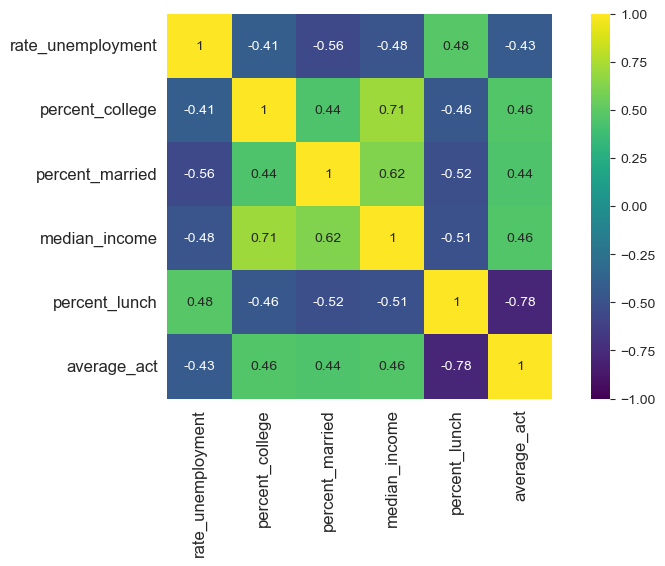

In [125]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'charter'

]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

This is a matrix with a heatmap color showing the correlation of the predictor values and the reponsive variable, as well as the correlation among those predictor variables. Numbers close to 1 and -1 have strong correlation, and close to 0 have a weak correlation.

### Make pair plots to explore relationships between the variables.

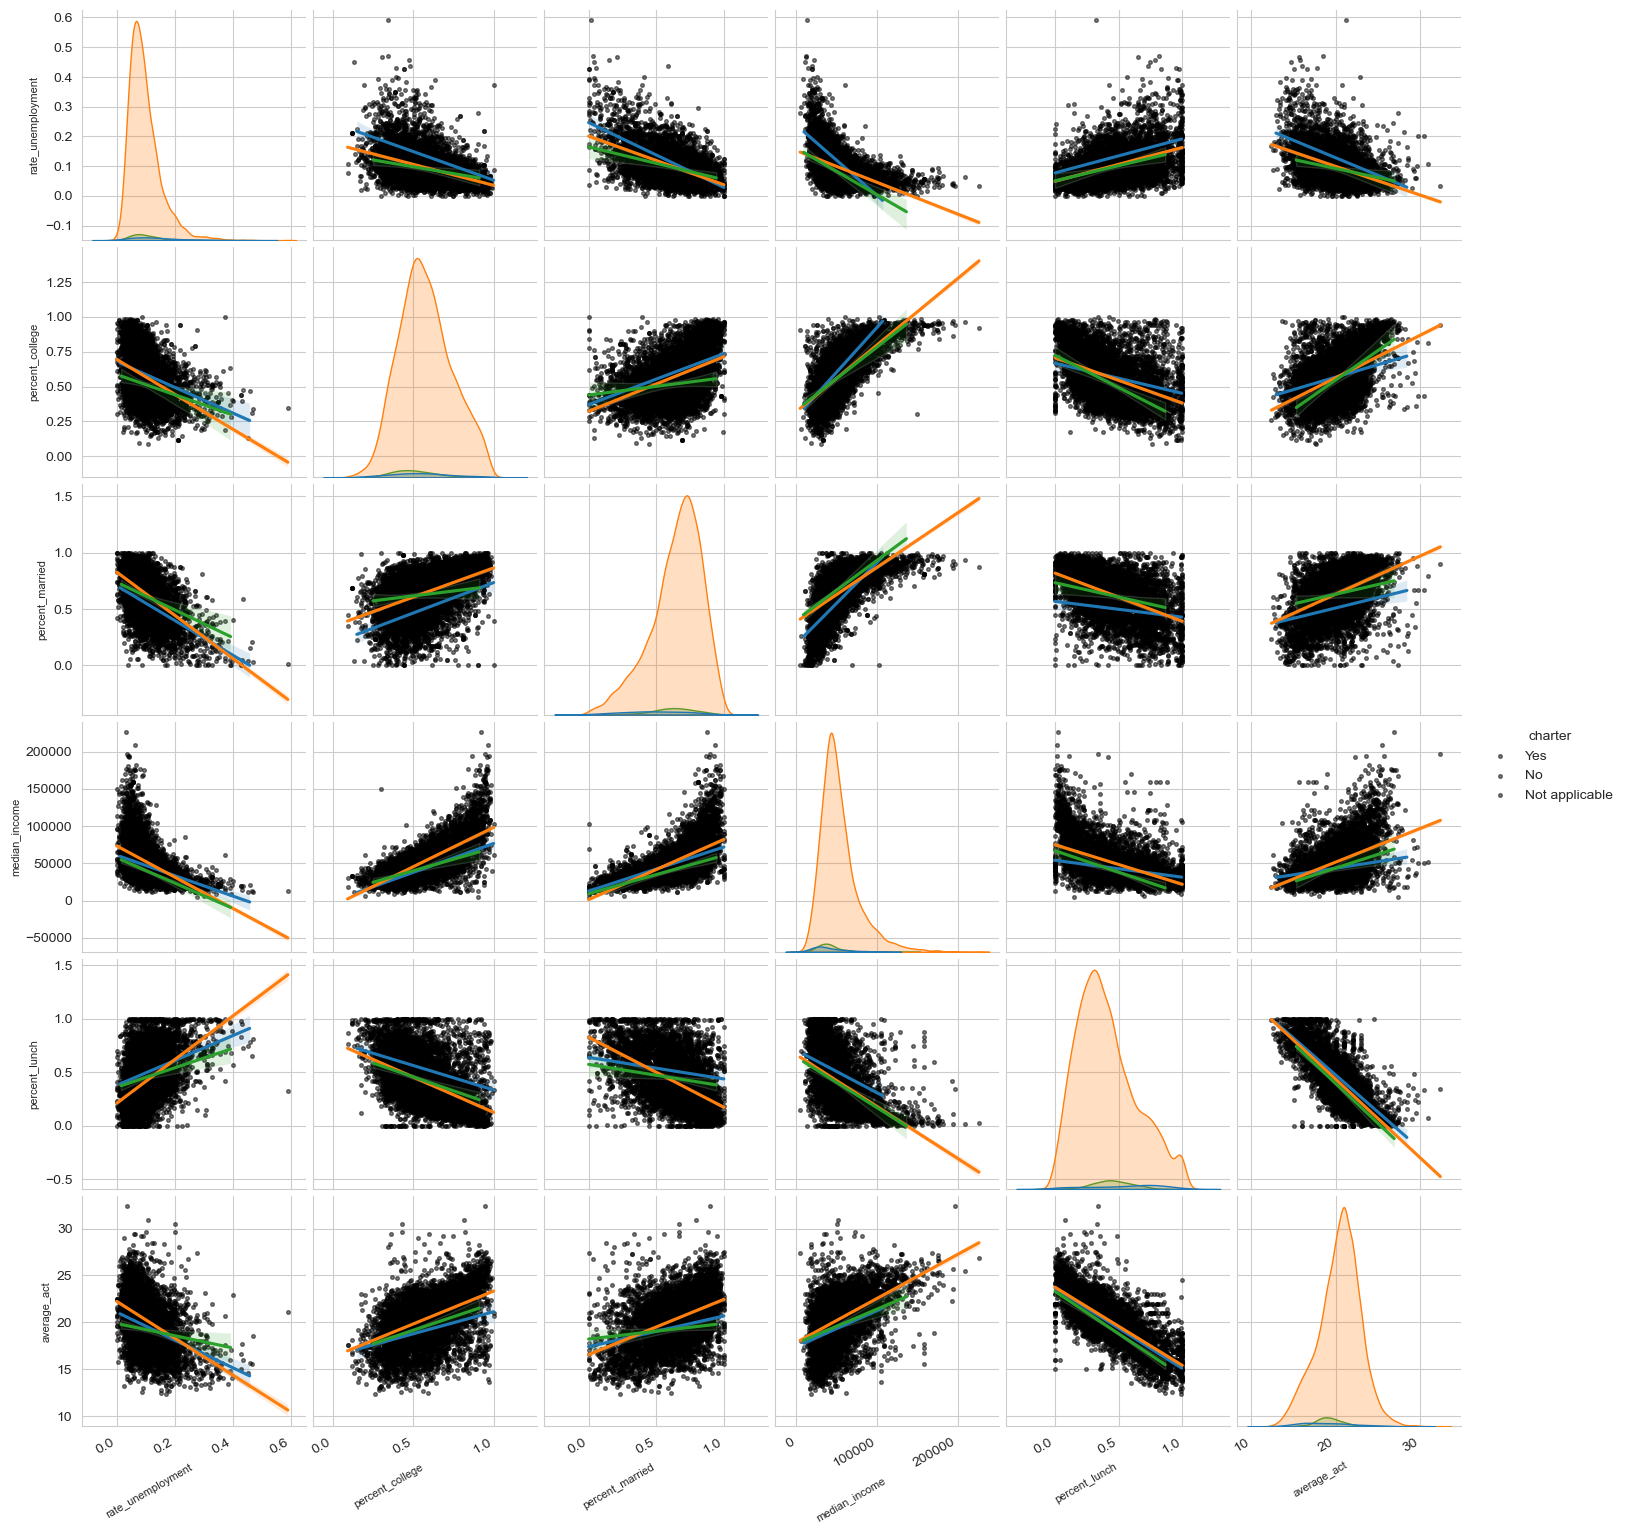

In [128]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

This is creating a pairplot to verify the correlation of a variable. We can also see outliers through the distributions.

### Identify outliers

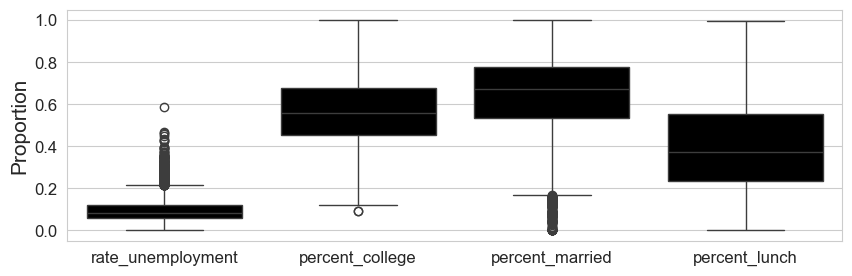

In [131]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

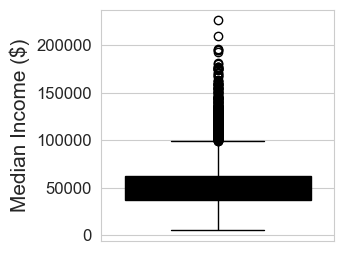

In [132]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

This is making a box plot to show the outliers.

### 5.2 Examine distributions and relationships

#### Plot the correlation matrix of the numerical variables in the data to explore relationships between the variables.

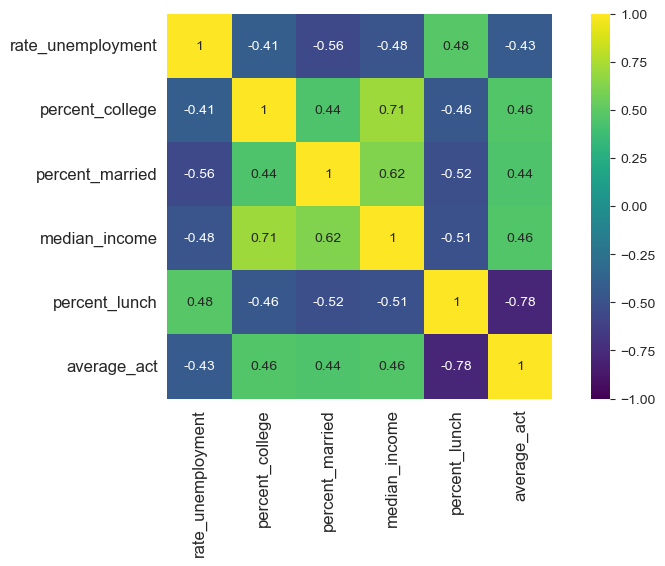

In [136]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

We will look at the correlation between average_act and the predictor variables, as well as the correlation among those predictor variables.

#### Make pair plots to explore relationships between the variables.

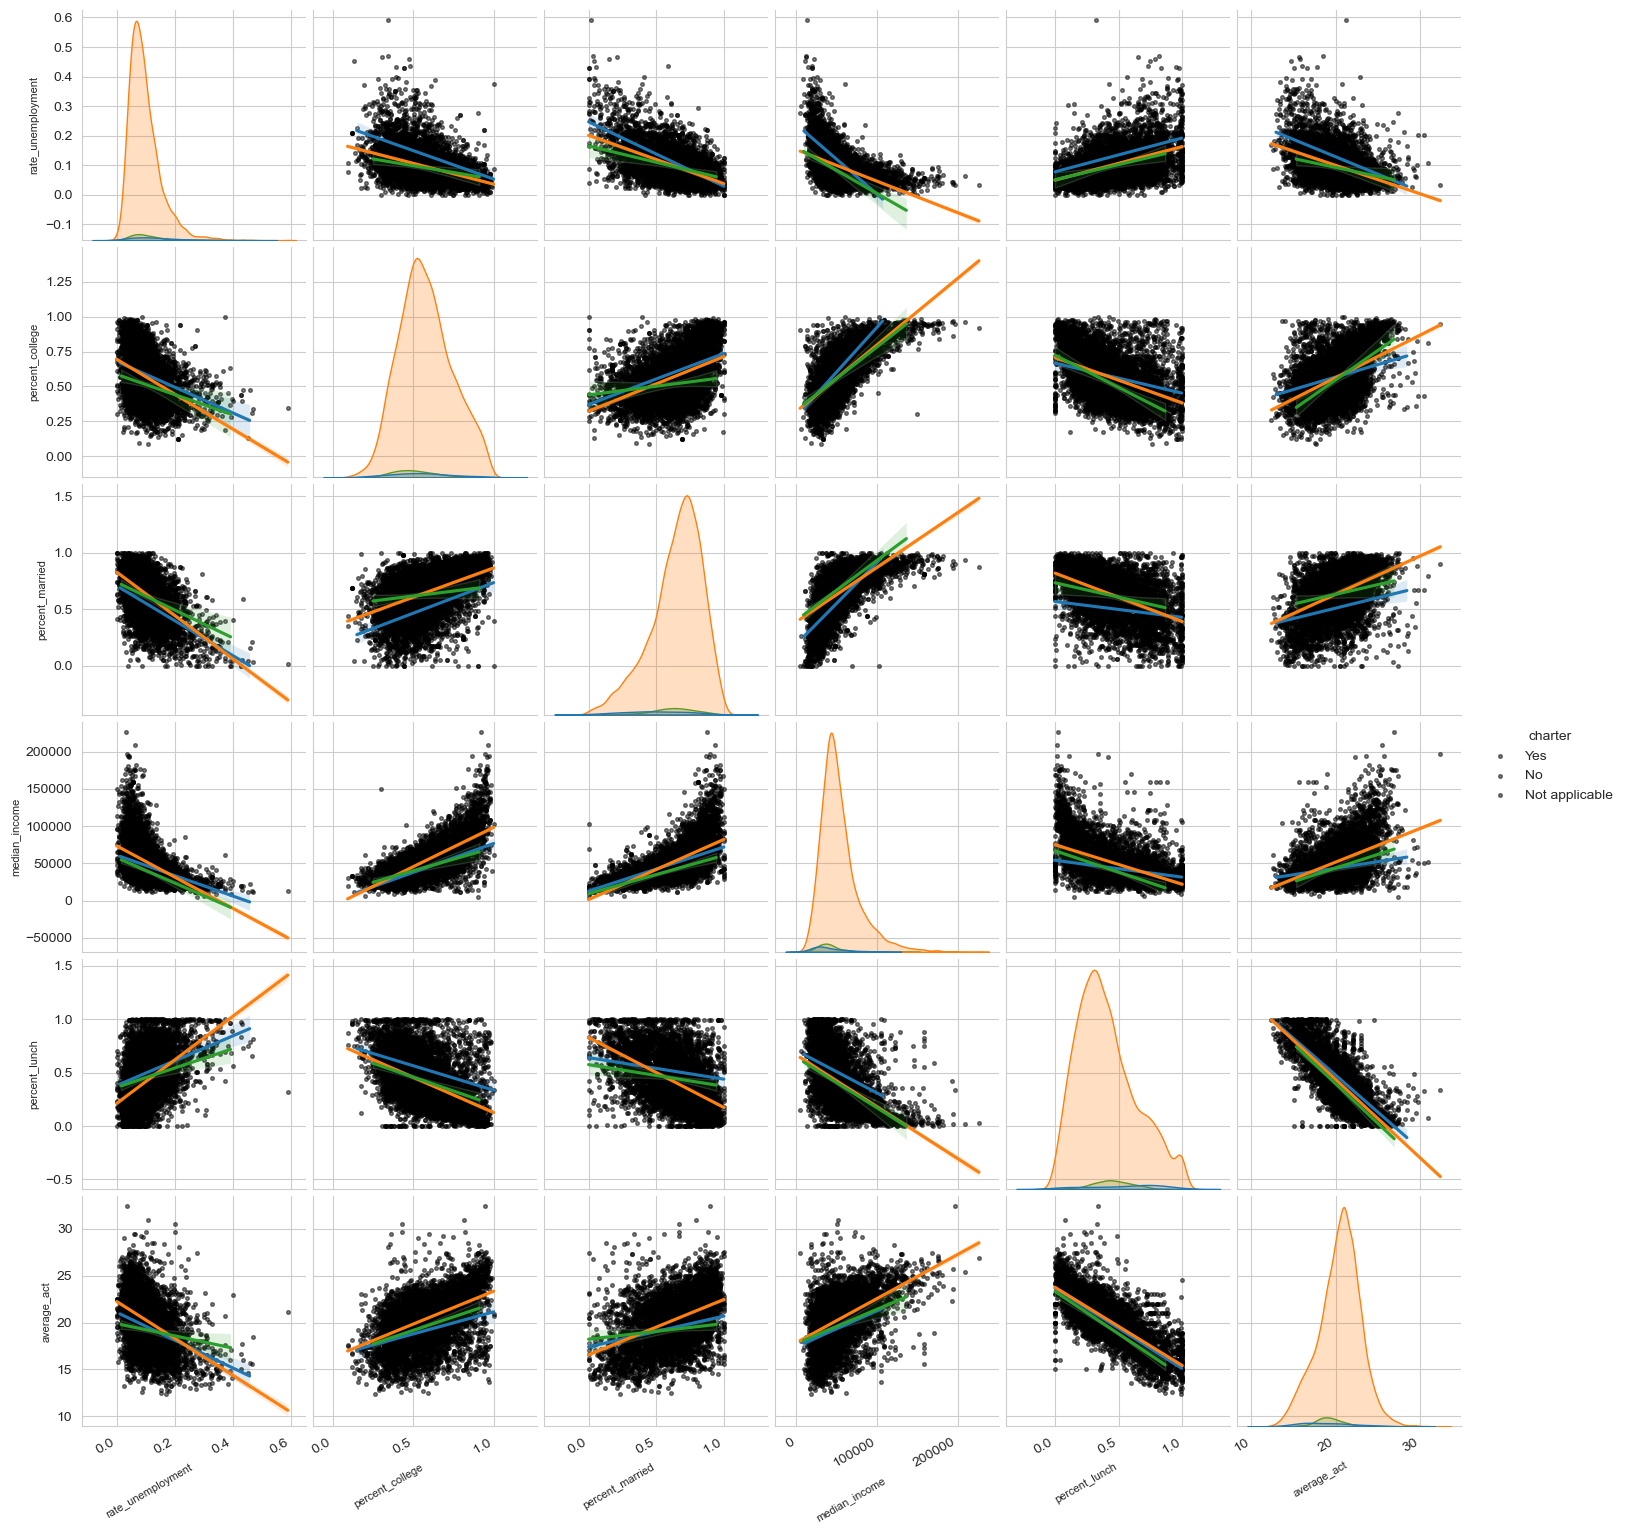

In [139]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

### 5.3 Identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median income is on a very different scale than the other predictors, so we will make two plots to explore the data.

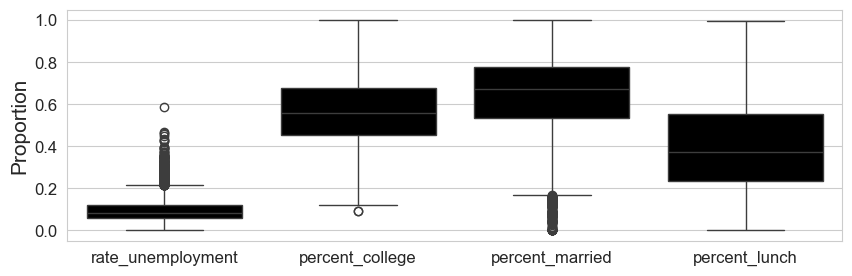

In [142]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

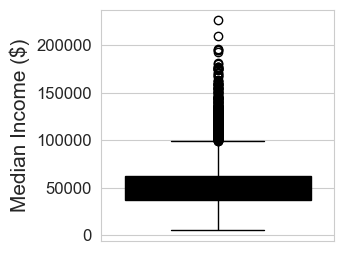

In [143]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

We noticed some unusual but reasonable values in unemployment, college education, marriage rates, and household income. We may need to adjust these variables to improve our models.

## 6.Modeling

### Single input models

Fit and assess models predicting the average ACT score from each of the input variables. You might try polynomial linear regression model, as appropriate.

### 6.1 Median income

#### Plot the regression line and the scatter plot

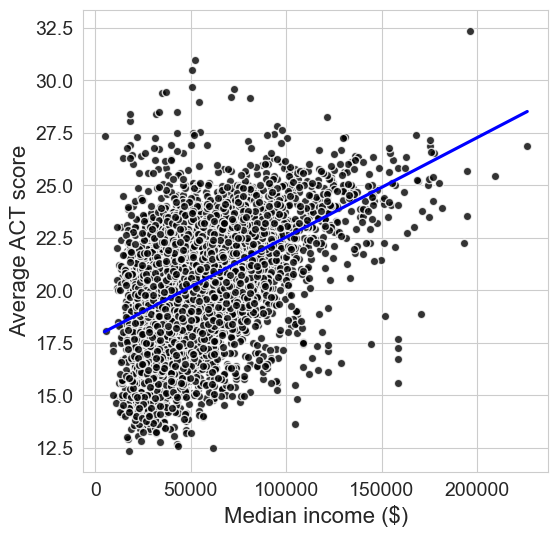

In [150]:
plt.figure(figsize=(6, 6))
sns.regplot(data=df, 
            x='median_income',
            y='average_act',
            color='blue',
            ci=False, 
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

#add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

#Increase the fontsize of the ticks labels
plt.tick_params(labelsize = 14)

plt.show()


We created a scatter plot with a regression line to explore the relationship between median household income and average ACT scores. Each black dot represents a school, while the blue line shows the overall trend. This helps us see whether schools in areas with higher household incomes tend to have higher ACT scores.

### 6.2 Fit the simple linear regression model

In [153]:
model_median_income = smf.ols(formula='average_act ~ median_income', data=df).fit()

First variable is the responsive, second variable is the predictive variable 

#### Display the fit summary: check the sign and significance of the coefficients

In [156]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.212
Model:                            OLS   Adj. R-squared:                  0.212
Method:                 Least Squares   F-statistic:                     1940.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:08   Log-Likelihood:                -16041.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.7990      0.063    284.782

We used linear regression to examine the relationship between median household income and average ACT scores across 7,227 schools. The results show a positive relationship, meaning schools in areas with higher household incomes tend to have higher ACT scores. For every $10,000 increase in household income, the predicted ACT score increases by approximately 0.47 points.

The R² value of 0.212 means that household income alone explains about 21.2% of the differences in ACT scores. The relationship is statistically significant (p < 0.001), but other factors are also important in understanding student performance.

### 6.3 Numerical assessment of fit accuracy

#### compute the R-squared

In [160]:
model_median_income.rsquared

0.21170631106406235

#### Compute the RMSE

In [162]:
y_hat = model_median_income.predict()

In [163]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

2.227

We calculated the Root Mean Squared Error (RMSE) to measure how far our predicted ACT scores are from the actual scores. A lower RMSE means the model makes more accurate predictions. This helps us understand how well household income alone predicts average ACT scores and gives us a value to compare with future models.

#### compute the mean absolute error

In [166]:
mean_absolute_error(df['average_act'], y_hat)

1.7126081786139729

We calculated the Mean Absolute Error (MAE) to measure the average difference between the actual ACT scores and the scores predicted by our model. A lower MAE means the predictions are closer to the real values. This helps us evaluate the model's accuracy and compare it with other models.

### 6.4 Use a residual plot for graphical assessment of model fit

Residual the error between the actual value and the predicted value.

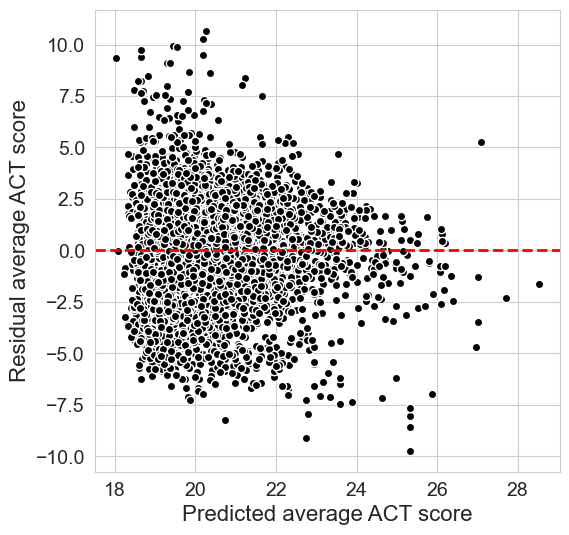

In [170]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_median_income.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The residuals are scattered around zero, but their spread is not constant across predicted values. There are also some outliers. This suggests possible heteroscedasticity (non constant variance), and indicates that the linear regression model may not fully capture the patterns in the data.

### 6.5 Try a quadratic model. Plot the regression curves and the scatter plot

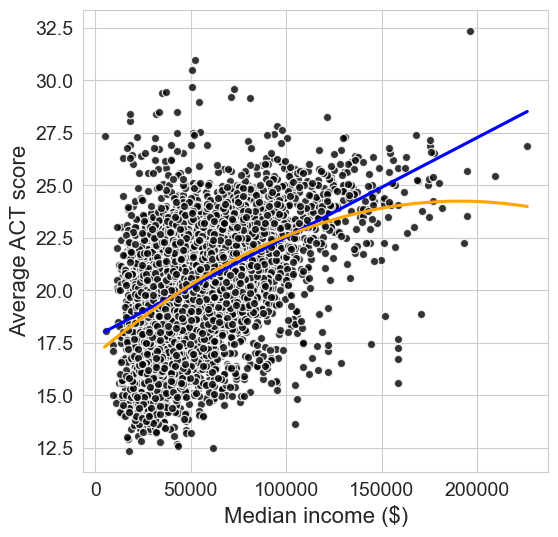

In [173]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           order = 2, # compute a quadratic regression line
           color = 'orange',
           ci = False,
           scatter = False)

# Add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

We created a scatter plot to compare two regression lines showing the relationship between household income and average ACT scores. The blue line represents a straight-line relationship, while the orange curve allows the relationship to change as income increases. This helps us see whether a curved model might describe the data better than a straight line.

In [175]:
model_median_income2 = smf.ols(
    formula = 'average_act ~ median_income + I(median_income**2)', # I is an indicator for the second term
    data = df).fit()

We created a quadratic regression model to explore the relationship between household income and average ACT scores. Unlike the previous model, this one includes income squared, allowing the relationship to follow a curve instead of a straight line. This will help us determine whether the quadratic model fits the data better than the linear model.

#### Display the fit summary

In [178]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.220
Model:                            OLS   Adj. R-squared:                  0.220
Method:                 Least Squares   F-statistic:                     1017.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:09   Log-Likelihood:                -16004.
No. Observations:                7227   AIC:                         3.201e+04
Df Residuals:                    7224   BIC:                         3.203e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.93

The quadratic model explains 22% of the differences in ACT scores (R² = 0.220), slightly more than the linear model (21.2%). Both income terms are statistically significant (p < 0.001), suggesting that ACT scores increase with household income, but at a slower rate for higher incomes. However, income alone still explains only a small portion of the differences in ACT scores.

#### Assess the model significance

In [181]:
model_median_income2.pvalues

Intercept                 0.000000e+00
median_income            4.720007e-100
I(median_income ** 2)     7.257471e-18
dtype: float64

We used .pvalues to check whether the variables in our quadratic regression model are statistically significant. Both median household income and its squared term have p-values below 0.001, indicating that they are statistically significant. This suggests that both terms contribute to explaining the relationship between household income and average ACT scores.

#### Compare two nested polynomial linear regression models: simpler model vs more complicated model

In [184]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35841.378061,0.0,NaN,NaN,NaN
1,7224.0,35475.367628,1.0,366.010433,74.532261,7.257471e-18


P-value indicated there's a statistically significant difference between these two models.

#### Assess the model accuracy

Compute the mean absolute error

In [188]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.6967468612836012

In [189]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.7126081786139729

### 6.6 Multiple linear regression

Fit multiple linear regression model using all socioeconomic variables as predictors. Your can also include other transformation for the current variables or include more variables in your model.

In [192]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch ',
    data = df).fit()

#### Print the summary

In [194]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:09   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6896      0.13

Our model explains 62.8% of the differences in average ACT scores (R² = 0.628), a significant improvement over using household income alone. Higher unemployment and free or reduced-price lunch eligibility are associated with lower ACT scores, while higher college education levels are associated with higher scores. These three factors are statistically significant (p < 0.001), while household income and marriage rates are not significant when the other factors are included.

#### Use a residual plot for graphical assessment of model fit

In [197]:
y_hat = model.predict()

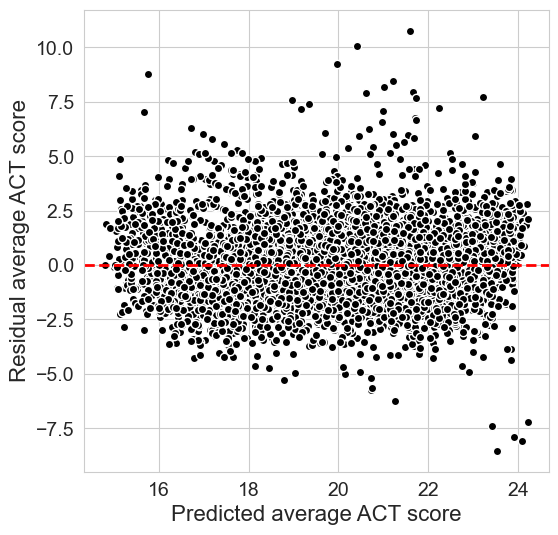

In [198]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

We created a residual plot to compare predicted ACT scores with the differences between predicted and actual scores. The red dashed line represents zero error. This helps us check whether the model's errors are randomly distributed or show patterns that could indicate problems with the model.

#### Compute the mean absolute error

In [201]:
mean_absolute_error(df['average_act'], model.predict())

1.1451433519015672

We calculated the Mean Absolute Error (MAE) to measure the average difference between actual and predicted ACT scores. A lower MAE indicates more accurate predictions and helps us compare this model with our previous models.

#### Print the summary for a the states multiple linear regression 

In [204]:
model_states = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch +  C(state, Treatment(reference="IL"))',
    data=df
).fit()

print(model_states.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     635.4
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:09   Log-Likelihood:                -12792.
No. Observations:                7227   AIC:                         2.563e+04
Df Residuals:                    7202   BIC:                         2.581e+04
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

We included states in our regression model, using Illinois (IL) as the reference for comparison. After accounting for socioeconomic factors, several states show statistically significant differences in ACT scores compared to Illinois. Higher college education levels are associated with higher ACT scores, while unemployment and free or reduced-price lunch eligibility are associated with lower scores. Household income and marriage rates remain statistically insignificant.

In [206]:
y_hat = model_states.predict()

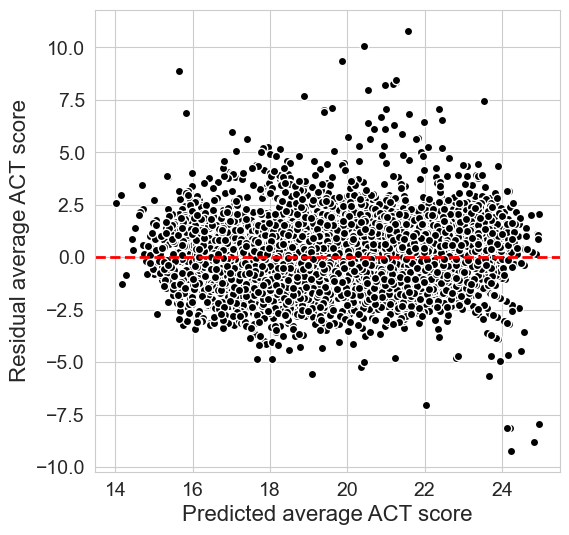

In [207]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_states.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

We created a residual plot to compare predicted ACT scores with the differences between predicted and actual scores. The red dashed line represents zero error. This helps us check whether the model's errors are randomly distributed or show patterns that could indicate problems with the model.

In [209]:
mean_absolute_error(df['average_act'], model_states.predict())

1.0276639579166078

We calculated the Mean Absolute Error (MAE) to measure the average difference between actual and predicted ACT scores. A lower MAE indicates more accurate predictions and helps us compare this model with our previous models.

In [211]:
print("Without states:", model.rsquared)
print("With states:", model_states.rsquared)

Without states: 0.628033371369038
With states: 0.6792049979850543


We compared the R² values of both models to see whether including states improves the results. The R² increased from 0.628 to 0.679, meaning the model with states explains 67.9% of the differences in ACT scores, compared to 62.8% without states. This suggests that including state information improves the model's fit.

#### Fit a reduced model with the significance predictors

In [214]:
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data = df).fit()

#### Print the summary

In [216]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4065.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:10   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6335      0.10

We created a simpler regression model using only unemployment rates, college education levels, and free or reduced-price lunch eligibility. All three factors are statistically significant (p < 0.001). Higher college education levels are associated with higher ACT scores, while higher unemployment and lunch eligibility rates are associated with lower scores. This suggests these three factors are important predictors of ACT performance.

#### Use a residual plot for graphical assessment of model fit.

In [219]:
y_hat = model_reduced.predict()

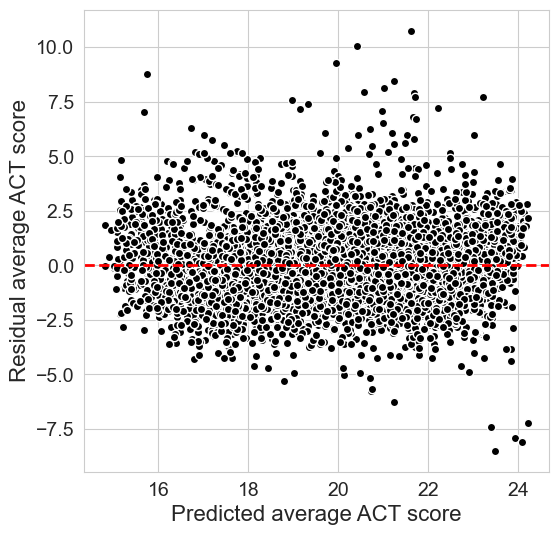

In [220]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_reduced.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

We created a residual plot to compare predicted ACT scores with the differences between predicted and actual scores. The red dashed line represents zero error. This helps us check whether the model's errors are randomly distributed or show patterns that could indicate problems with the model.

#### Compute the mean absolute error

In [223]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1452767303150333

We calculated the Mean Absolute Error (MAE) to measure the average difference between actual and predicted ACT scores. A lower MAE indicates more accurate predictions and helps us compare this model with our previous models.

#### Compare the accurary between full and reduced models

In [226]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_states = mean_absolute_error(df['average_act'], model_states.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())


r2_full = model.rsquared
r2_states = model_states.rsquared
r2_reduced = model_reduced.rsquared


pd.DataFrame({'Mean Absolute Error': [mae_full, mae_states, mae_reduced],
             'R-squared': [r2_full, r2_states, r2_reduced]},
            index = ['full model', 'states model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1451,0.6280
states model,1.0277,0.6792
reduced model,1.1453,0.6280


We compared the full, states, and reduced regression models using Mean Absolute Error (MAE) and R². A lower MAE indicates more accurate predictions, while a higher R² means the model explains more differences in ACT scores. This comparison helps us identify which model performs best and whether including additional variables improves the results.

### Use an ANOVA to test the significance of difference between models

In [229]:
anova_lm(model_reduced, model, model_states)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16913.142693,0.0,NaN,NaN,NaN
1,7221.0,16912.220344,2.0,0.922349,0.227716,7.963558e-01
2,7202.0,14585.598120,19.0,2326.622224,60.464595,2.412748e-214


## 7. Scaling

### 7.1 Scale the predictor variables in the reduced model to have mean 0 and standard deviation 1 and add them to the data frame

In [232]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

In [233]:
# create a list of names of these scaled columns
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


In [234]:
# standardize/normalize
scaler = StandardScaler().fit(df[predictor_variables])

In [235]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

We used StandardScaler to standardize our predictor variables so they have a mean of 0 and a standard deviation of 1. First, we used fit() to calculate the mean and standard deviation of each variable, then transform() to apply the scaling. We saved the results in new columns ending with _normalized, keeping the original values for comparison.

#### Check the mean and standard deviation of the transformed data.

In [238]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,0.0,0.0,-0.0
std,1.0,1.0,1.0


#### Fit the multiple linear regression model with the normalized predictors

In [240]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

We calculated the mean and standard deviation of our standardized variables to confirm that scaling worked correctly. The expected results are a mean close to 0 and a standard deviation close to 1 for each variable.

#### Print the summary

In [243]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4065.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:10   Log-Likelihood:                -13327.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

The standardized model explains 62.8% of the differences in ACT scores (R² = 0.628). All three predictors are statistically significant (p < 0.001). Free or reduced-price lunch eligibility has the strongest relationship with ACT scores, followed by college education and unemployment. The results also show that standardizing the variables does not change the model's overall fit.

In [245]:
model_states_normalized = smf.ols(
    formula='average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized + C(state, Treatment(reference="IL"))',
    data=df
).fit()

print(model_states_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     693.3
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:10   Log-Likelihood:                -12792.
No. Observations:                7227   AIC:                         2.563e+04
Df Residuals:                    7204   BIC:                         2.579e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

We included states and standardized socioeconomic variables in our regression model, using Illinois as the reference state. Free or reduced-price lunch eligibility has the strongest negative relationship with ACT scores, while college education has a positive relationship. Unemployment also has a smaller negative relationship. All three predictors are statistically significant (p < 0.01), and several states show significant differences compared to Illinois.

### 7.2 Compare the accurary between full and reduced models

In [248]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())
mae_states_normalized = mean_absolute_error(df['average_act'], model_states_normalized.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared
r2_states_normalized =  model_states_normalized.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced, mae_states_normalized],
             'R-squared': [r2_normalized, r2_reduced, r2_states_normalized]},
            index = ['normalized model', 'reduced model', 'states normalized']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1453,0.6280
reduced model,1.1453,0.6280
states normalized,1.0276,0.6792


The normalized and reduced models have identical results (MAE = 1.1453, R² = 0.628), showing that standardization does not improve prediction accuracy. However, including states improves the model, reducing MAE to 1.0276 and increasing R² to 0.6792. This suggests that state information helps explain differences in ACT scores.